## **YouTube Comment Sentiment Analysis Using Support Vector Machine (SVM)**
This project aims to classify the sentiment (Positive/Negative) of public comments on YouTube regarding political or economic issues. The method used is **Support Vector Machine (SVM)** with complete natural language preprocessing steps (Cleaning, Stopword Removal, Slang Normalization, and Stemming using the Nazief & Adriani algorithm).

### **1. External Libraries Installation**
The first step is to install external libraries that are not available by default:
* **Sastrawi:** Specialized NLP library for Indonesian language, used for Stemming and Stopword Removal.
* **youtube-comment-downloader:** A tool to scrape comment data without requiring an API Key.
* **imbalanced-learn:** A library containing the SMOTE algorithm to handle imbalanced datasets.

In [56]:
# pip install Sastrawi youtube-comment-downloader imbalanced-learn

### **2. Data Acquisition (Scraping)**
In this stage, comment data is scraped from relevant YouTube videos. The script below functions to:
1. Detect the video ID from the provided URL.
2. Automatically fetch comments (targeting > 500 data points).
3. Save the raw data into an Excel format (`.xlsx`) for readability.

In [57]:
import pandas as pd
from youtube_comment_downloader import YoutubeCommentDownloader, SORT_BY_POPULAR
from itertools import islice
import time
import re

def clean_text_for_excel(text):
    if not isinstance(text, str):
        return ""
    text = text.replace('\n', ' ').replace('\r', ' ').replace('\t', ' ')
    return " ".join(text.split())

def get_video_id(url):
    url = url.strip()
    
    # 1. Format: https://www.youtube.com/watch?v=ID
    if "v=" in url:
        return url.split("v=")[1].split("&")[0]
        
    # 2. Format: https://youtu.be/ID (Link Share)
    elif "youtu.be/" in url:
        return url.split("youtu.be/")[1].split("?")[0]
        
    # 3. Format: https://www.youtube.com/live/ID (Link Live Streaming) 
    elif "/live/" in url:
        return url.split("/live/")[1].split("?")[0]
        
    # 4. Format: https://www.youtube.com/shorts/ID (Link Shorts)
    elif "/shorts/" in url:
        return url.split("/shorts/")[1].split("?")[0]
        
    # 5. Format input ID 
    elif len(url) == 11 and "http" not in url:
        return url
        
    return None

def main():
    print("Enter Video Link:")
    try:
        raw_url = input("> ")
    except (EOFError, KeyboardInterrupt):
        print("\nInput cancelled by user.")
        return

    video_id = get_video_id(raw_url)
    
    if not video_id:
        print(f"Failed to extract ID from: {raw_url}")
        print("Ensure the link is correct or input the ID directly.")
        return

    print(f"Detected ID: {video_id}")
    print("Fetching data...")

    downloader = YoutubeCommentDownloader()
    
    try:
        clean_url = f"https://www.youtube.com/watch?v={video_id}"
        comments = downloader.get_comments_from_url(clean_url, sort_by=SORT_BY_POPULAR)
        data = []
        limit = 650 
        
        for i, comment in enumerate(islice(comments, limit)):
            data.append({
                'username': comment['author'],
                'text': clean_text_for_excel(comment['text']),
                'time': comment['time']
            })
            
            if (i + 1) % 50 == 0:
                print(f"--> Retrieved {i + 1} comments...")

        df = pd.DataFrame(data)
        file_name = f"data_youtube_{video_id}.xlsx"
        
        df.to_excel(file_name, index=False, engine='openpyxl')
        
        print("\n" + "="*40)
        print(f"SUCCESS! {len(data)} comments saved.")
        print(f"File: {file_name}")
        print("="*40)

    except Exception as e:
        print(f"\n Error: {e}")

if __name__ == "__main__":
    main()

Enter Video Link:
Failed to extract ID from: 
Ensure the link is correct or input the ID directly.


### **3. Data Merging & Labeling Preparation**
Since the data might be collected from several different videos, this stage merges all Excel files from the scraping process into a single dataset (`dataset_siap_labeling.xlsx`).

This script will also:
* Remove exact duplicate comments.
* Prepare an empty `label` column for the manual labeling process (Human Annotation).

In [58]:
import pandas as pd
import glob
import os

def main():
    print("=== EXCEL MERGE PROGRAM (.xlsx) ===")
    files = glob.glob("data_youtube_*.xlsx")
    
    if not files:
        print("No files found!")
        return

    print(f"Found {len(files)} file(s) to merge:")
    for f in files:
        print(f" - {f}")

    all_data = []
    for file in files:
        try:
            df = pd.read_excel(file)
            all_data.append(df)
        except Exception as e:
            print(f"Failed to read file {file}: {e}")

    if not all_data:
        print("Failed to read all files.")
        return

    combined_df = pd.concat(all_data, ignore_index=True)
    initial_total = len(combined_df)
    
    # Remove duplicates
    combined_df.drop_duplicates(subset=['text'], inplace=True)
    final_total = len(combined_df)

    combined_df['label'] = '' 

    output_name = "dataset_siap_labeling.xlsx"
    combined_df.to_excel(output_name, index=False)
    
    print("\n" + "="*40)
    print(f"MERGE SUCCESSFUL!")
    print(f"Initial Total Data : {initial_total}")
    print(f"Clean Data         : {final_total} ({initial_total - final_total} duplicates removed)")
    print(f"Output File        : {output_name}")
    print("="*40)

if __name__ == "__main__":
    main()

=== EXCEL MERGE PROGRAM (.xlsx) ===
No files found!


### **4. Text Preprocessing**
This is a crucial stage to clean the dirty text data so it is ready to be processed by the Machine Learning algorithm.

The Preprocessing steps include:
1. **Cleaning:** Removing URLs, numbers, punctuation, mentions, and emojis using Regex.
2. **Case Folding:** Converting all characters to lowercase.
3. **Normalization:** Correcting slang words into formal words using an external dictionary.
4. **Stopword Removal:** Removing meaningless conjunctions (e.g., "dan", "yang", "di").
5. **Stemming:** Converting affixed words to their base words using the **Sastrawi** library.

In [59]:
import io
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns

# Indonesian NLP Libraries
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

CORE_SLANG_FALLBACK = {
    "yg": "yang",
    "gak": "tidak",
    "ga": "tidak",
    "nggak": "tidak",
    "gk": "tidak",
    "tdk": "tidak",
    "bgt": "banget",
    "klo": "kalau",
    "kalo": "kalau",
    "bikin": "membuat",
    "udh": "sudah",
    "udah": "sudah",
    "blm": "belum",
    "krn": "karena",
    "tp": "tapi",
    "dgn": "dengan",
    "aja": "saja",
    "mantul": "mantap betul",
    "bohong": "bohong",
    "parah": "parah",
}


def load_slang_dictionary(timeout: int = 10) -> dict[str, str]:
    print("Downloading slang dictionary...")
    url = "https://raw.githubusercontent.com/nasalsabila/kamus-alay/master/colloquial-indonesian-lexicon.csv"
    try:
        response = requests.get(url, timeout=timeout)
        response.raise_for_status()
        df_slang = pd.read_csv(io.StringIO(response.content.decode("utf-8"))).dropna(
            subset=["slang", "formal"]
        )
        remote_dict = dict(
            zip(
                df_slang["slang"].astype(str).str.strip(),
                df_slang["formal"].astype(str).str.strip(),
            )
        )
        merged = {**CORE_SLANG_FALLBACK, **remote_dict}
        print("Slang dictionary loaded successfully!")
        return merged
    except (requests.RequestException, ValueError, KeyError, UnicodeDecodeError) as e:
        print(f"Failed to download slang dictionary ({e}); using built-in fallback dictionary.")
        return dict(CORE_SLANG_FALLBACK)


print("Initializing Nazief Adriani Stemmer (Sastrawi)...")
factory = StemmerFactory()
stemmer = factory.create_stemmer()

stop_factory = StopWordRemoverFactory()
custom_stopwords = [
    "dan", "atau", "yg", "juga", "dari", "di", "ke",
    "nya", "roy", "sih", "deh", "dong", "kok", "kan",
    "ini", "itu", "aja", "kalau", "kalo", "buat",
]
stopword_set = set(stop_factory.get_stop_words()) | set(custom_stopwords)
SLANG_DICT = load_slang_dictionary()


# Preprocessing Function
def text_preprocessing(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()

    # 1. Cleaning (Regex)
    text = re.sub(r"http\S+|www\S+|https\S+", "", text, flags=re.MULTILINE)
    text = re.sub(r"@\w+|#\w+", "", text)
    text = re.sub(r"\d+", "", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    # 2. Slang Correction & Stopword Removal
    words = text.split()
    clean_words = []

    for word in words:
        for normalized in SLANG_DICT.get(word, word).split():
            if normalized not in stopword_set:
                clean_words.append(normalized)

    text = " ".join(clean_words)

    # 3. Stemming
    text = stemmer.stem(text)
    return text

Initializing Nazief Adriani Stemmer (Sastrawi)...
Slang dictionary loaded successfully!


### **5. Applying Preprocessing to Dataset**
In this block, we load the manually labeled dataset, filter the valid labels, apply the `text_preprocessing` function, and save the clean data.

In [60]:
print("\n=== DATA LOADING & PREPROCESSING ===")

file_name = "dataset_siap_labeling.xlsx"
try:
    df = pd.read_excel(file_name)
    print(f"Data loaded: {len(df)} rows.")
except (FileNotFoundError, ValueError, OSError) as exc:
    print(f"Failed to open file '{file_name}': {exc}")
    raise FileNotFoundError(f"Could not load Excel dataset '{file_name}'") from exc

if 'label' not in df.columns:
    print("No 'label' column found. Check the Excel file!")
    raise ValueError("Missing required 'label' column in Excel file.")
    
# Filtering Labels
df['label'] = df['label'].astype(str)
df['label'] = df['label'].str.lower().str.strip()
print(f"Labels found: {df['label'].unique()}") 

df = df[df['label'].isin(['positif', 'negatif'])]

if len(df) == 0:
    print("\nDATA IS EMPTY AFTER FILTERING!")
    raise ValueError("No valid rows found after filtering for 'positif' and 'negatif'.")
print(f"Valid data (labeled): {len(df)} rows.")

# Preprocessing Execution
print("\nApplying preprocessing to the text column. This may take a while...")
df['text'] = df['text'].astype(str)
df['text_clean'] = df['text'].apply(text_preprocessing)

# Remove empty rows after cleaning
df = df[df['text_clean'] != '']
print(f"Remaining data after cleaning: {len(df)} rows.")

df.to_excel("hasil_preprocessing.xlsx", index=False)
print("Preprocessing complete! Results saved to 'hasil_preprocessing.xlsx'")


=== DATA LOADING & PREPROCESSING ===
Data loaded: 502 rows.
Labels found: ['positif' 'negatif']
Valid data (labeled): 502 rows.

Applying preprocessing to the text column. This may take a while...
Remaining data after cleaning: 500 rows.
Preprocessing complete! Results saved to 'hasil_preprocessing.xlsx'


### **6. Feature Extraction (TF-IDF) & Data Splitting**
Transforming text data into numerical vectors using `TfidfVectorizer` with Bigram (`ngram_range=(1, 2)`). Then, the dataset is split into 80% Training and 20% Testing sets.

In [61]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

print("\n=== DATA SPLITTING & FEATURE EXTRACTION ===")

X = df['text_clean']
y = df['label']

print("--> Splitting data into Train and Test sets FIRST (Preventing Data Leakage)...")
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("--> Extracting features using TF-IDF (Unigram & Bigram)...")
vectorizer = TfidfVectorizer(ngram_range=(1, 2), max_features=2000)

X_train = vectorizer.fit_transform(X_train_raw)
X_test = vectorizer.transform(X_test_raw)

print(f"\nTraining Data Shape : {X_train.shape[0]} rows")
print(f"Test Data Shape     : {X_test.shape[0]} rows")
print(f"Training Label Distribution:\n{y_train.value_counts()}")


=== DATA SPLITTING & FEATURE EXTRACTION ===
--> Splitting data into Train and Test sets FIRST (Preventing Data Leakage)...
--> Extracting features using TF-IDF (Unigram & Bigram)...

Training Data Shape : 400 rows
Test Data Shape     : 100 rows
Training Label Distribution:
label
negatif    317
positif     83
Name: count, dtype: int64


### **7. Model Training & Cross Validation**
Training the Support Vector Machine (SVM) model on the balanced data. We also evaluate the model's stability during training using 5-Fold Cross Validation.

### **Support Vector Machine (SVM) with Hyperparameter Tuning**
To handle the cleaned and balanced data optimally, we apply `GridSearchCV`. This technique exhaustively searches through a specified parameter grid (combinations of `C`, `kernel`, and `gamma`) to find the best performing SVM configuration using Cross-Validation.

In [62]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
import numpy as np

print("\n=== SVM HYPERPARAMETER TUNING & MODELING ===")

param_grid = {
    'C': [0.1, 1, 10], 
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}

print("--> Initializing GridSearchCV to find the best SVM parameters...")
grid = GridSearchCV(SVC(class_weight='balanced', random_state=42), param_grid, refit=True, verbose=2, cv=5, scoring='f1_macro', n_jobs=-1)

print("--> Training and Tuning the SVM model on Original Data with Class Weights...")
grid.fit(X_train, y_train) 

print(f"\n[SUCCESS] Best Parameters Found: {grid.best_params_}")
print(f"[SUCCESS] Best Cross-Validation F1-Macro Score: {grid.best_score_:.4f}")

print("\n--> Predicting on Unseen Test Data using the Best Model...")
y_pred = grid.predict(X_test)


=== SVM HYPERPARAMETER TUNING & MODELING ===
--> Initializing GridSearchCV to find the best SVM parameters...
--> Training and Tuning the SVM model on Original Data with Class Weights...
Fitting 5 folds for each of 12 candidates, totalling 60 fits

[SUCCESS] Best Parameters Found: {'C': 1, 'gamma': 'scale', 'kernel': 'linear'}
[SUCCESS] Best Cross-Validation F1-Macro Score: 0.6653

--> Predicting on Unseen Test Data using the Best Model...


### **8. Evaluation & Confusion Matrix**
Measuring the final performance of the model using Accuracy, Precision, Recall, and F1-Score metrics, alongside a visual representation using a Confusion Matrix.


       SVM MODEL EVALUATION (UNSEEN TEST DATA)
Accuracy : 82.00%

Comprehensive Report:
              precision    recall  f1-score   support

     negatif       0.86      0.93      0.89        80
     positif       0.57      0.40      0.47        20

    accuracy                           0.82       100
   macro avg       0.72      0.66      0.68       100
weighted avg       0.80      0.82      0.81       100


Confusion Matrix graphic saved as: 'confusion_matrix_final.png'


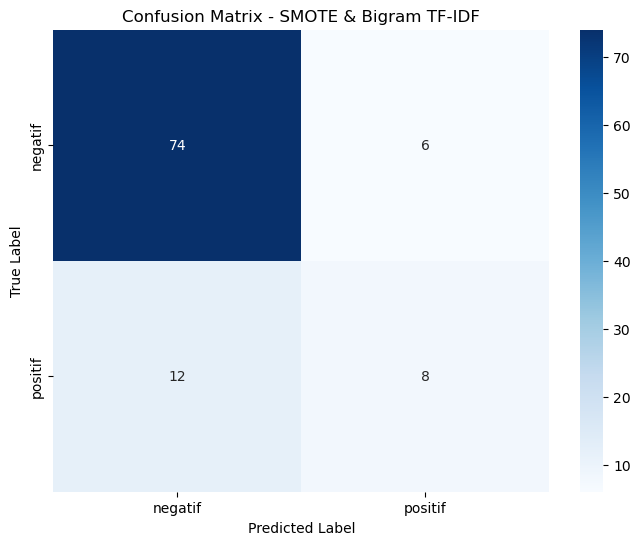

In [63]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print("\n" + "="*50)
print("       SVM MODEL EVALUATION (UNSEEN TEST DATA)")
print("="*50)

acc = accuracy_score(y_test, y_pred)
print(f"Accuracy : {acc*100:.2f}%")
print("\nComprehensive Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion Matrix Visualization
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))

labels_in_test = sorted(list(set(y_test)))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=labels_in_test, 
            yticklabels=labels_in_test)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Class-Weighted SVM & Bigram TF-IDF')

plt.savefig('confusion_matrix_final.png')
print("\nConfusion Matrix graphic saved as: 'confusion_matrix_final.png'")
print("="*50)
plt.show()

### **9. WordCloud Visualization**
To better understand the context of the dataset, we generate a WordCloud for each sentiment class. This visualization helps in identifying the most frequent terms used by the public in positive and negative comments.


=== WORDCLOUD: POSITIVE SENTIMENT ===


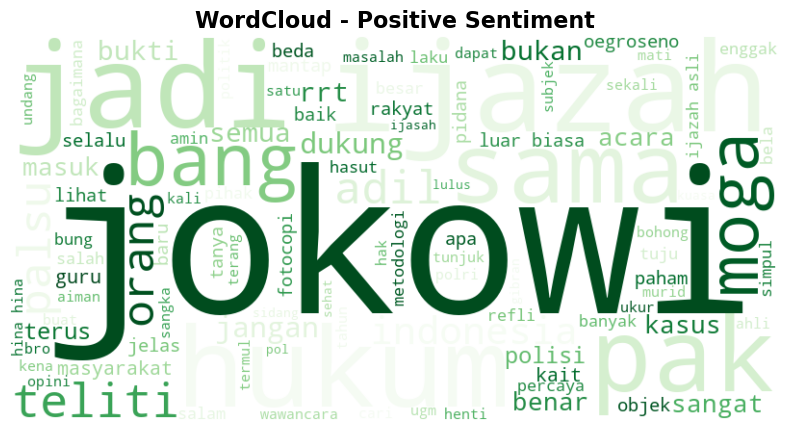

WordCloud saved as: 'wordcloud__positive_sentiment.png'

=== WORDCLOUD: NEGATIVE SENTIMENT ===


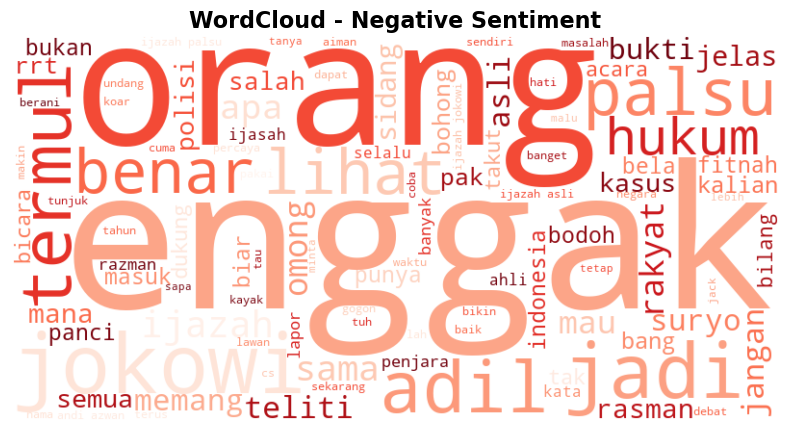

WordCloud saved as: 'wordcloud__negative_sentiment.png'


In [64]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

text_positive = ' '.join(df[df['label'] == 'positif']['text_clean'])
text_negative = ' '.join(df[df['label'] == 'negatif']['text_clean'])

# Function to generate and plot WordCloud
def plot_wordcloud(text, title, colormap):
    if not isinstance(text, str) or not text.strip():
        print(f"Skipping WordCloud '{title}': no non-empty tokens available.")
        return
    wordcloud = WordCloud(width=800, height=400, 
                          background_color='white', 
                          colormap=colormap, 
                          max_words=100).generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.title(title, fontsize=16, fontweight='bold')
    plt.axis('off')

    # Save the figure dynamically based on the title
    file_name = title.lower().replace(' ', '_').replace('-', '') + '.png'
    plt.savefig(file_name)
    plt.show()
    print(f"WordCloud saved as: '{file_name}'")

print("\n" + "="*50)
print("=== WORDCLOUD: POSITIVE SENTIMENT ===")
print("="*50)
plot_wordcloud(text_positive, 'WordCloud - Positive Sentiment', 'Greens')

print("\n" + "="*50)
print("=== WORDCLOUD: NEGATIVE SENTIMENT ===")
print("="*50)
plot_wordcloud(text_negative, 'WordCloud - Negative Sentiment', 'Reds')

### **10. Model Export for Deployment**
To use this trained model in a real-world production environment (such as a web application or REST API), we need to serialize and export it. We use the `joblib` library to save two critical components:
1. **The Trained SVM Model:** The best estimator found via GridSearchCV.
2. **The TF-IDF Vectorizer:** Saving the vectorizer is crucial because any new, unseen text input must be transformed using the exact same vocabulary and feature space learned during the training phase.

In [65]:
import joblib

print("\n=== SAVING MODEL FOR DEPLOYMENT ===")
joblib.dump(grid.best_estimator_, 'svm_sentiment_model.pkl')
print("--> SVM Model saved as 'svm_sentiment_model.pkl'")

joblib.dump(vectorizer, 'tfidf_vectorizer.pkl')
print("--> TF-IDF Vectorizer saved as 'tfidf_vectorizer.pkl'")
print("\n[SUCCESS] Pipeline is ready for Production!")


=== SAVING MODEL FOR DEPLOYMENT ===
--> SVM Model saved as 'svm_sentiment_model.pkl'
--> TF-IDF Vectorizer saved as 'tfidf_vectorizer.pkl'

[SUCCESS] Pipeline is ready for Production!
